# BCI Competition IV-2a (BNCI2014_001) - LOSO Statistical & Summary Analysis

This notebook performs comprehensive performance aggregation and statistical significance testing (Wilcoxon Signed-Rank Test) across all 9 subjects using the Leave-One-Subject-Out (LOSO) evaluation protocol for **EEGNet**, **CvT**, and **ViT-PE** models.

## Objectives:
1. **Summary Metrics Extraction:** Compute Mean $\pm$ Standard Deviation for Accuracy, F1-Score, ROC-AUC, Specificity, Precision, and Recall across 9 folds.
2. **Statistical Significance Testing:** Execute pairwise Wilcoxon signed-rank tests to evaluate performance differences between Transformer-based models and the baseline EEGNet.
3. **Export Results:** Save the aggregated benchmark table (`bci2a_loso_summary_metrics.csv`) for manuscript revision and reviewer response documents.

Verified strict subject alignment across all 9 folds using column 'test_subject'.

--- Summary Performance Table (LOSO - 9 Subjects) ---


,Model,Accuracy (%),F1-Score (%),ROC-AUC (%),Specificity (%),Precision (%),Recall (%),Mean Train Time (s)
0,EEGNET,63.60 ± 7.94,63.76 ± 10.53,68.94 ± 10.37,61.95 ± 17.83,65.32 ± 9.12,65.23 ± 17.34,637.4s
1,CVT,54.14 ± 6.13,61.36 ± 11.42,55.68 ± 9.21,31.38 ± 24.36,53.73 ± 4.95,76.06 ± 22.66,401.7s
2,VIT_PE,50.71 ± 2.43,52.95 ± 7.22,50.08 ± 3.05,44.71 ± 15.97,51.57 ± 2.16,56.51 ± 16.57,134.7s


Saved summary metrics to: ../results/bci2a_loso_summary_metrics.csv

--- Statistical Significance Test Results (Holm-Bonferroni Corrected) ---


,Comparison,Superior Model,Mean Diff (%),Wilcoxon W,p_raw,p_holm,Effect Size (r),Significant (p_holm < 0.05)
0,CvT vs EEGNet,EEGNet,-9.46,1.0,0.007812,0.015625,0.887,True
1,ViT-PE vs EEGNet,EEGNet,-12.90,0.0,0.003906,0.011719,0.962,True
2,CvT vs ViT-PE,No Significant Difference,3.44,13.0,0.300781,0.300781,0.345,False


Saved statistical test results to: ../results/bci2a_statistical_significance_results.csv


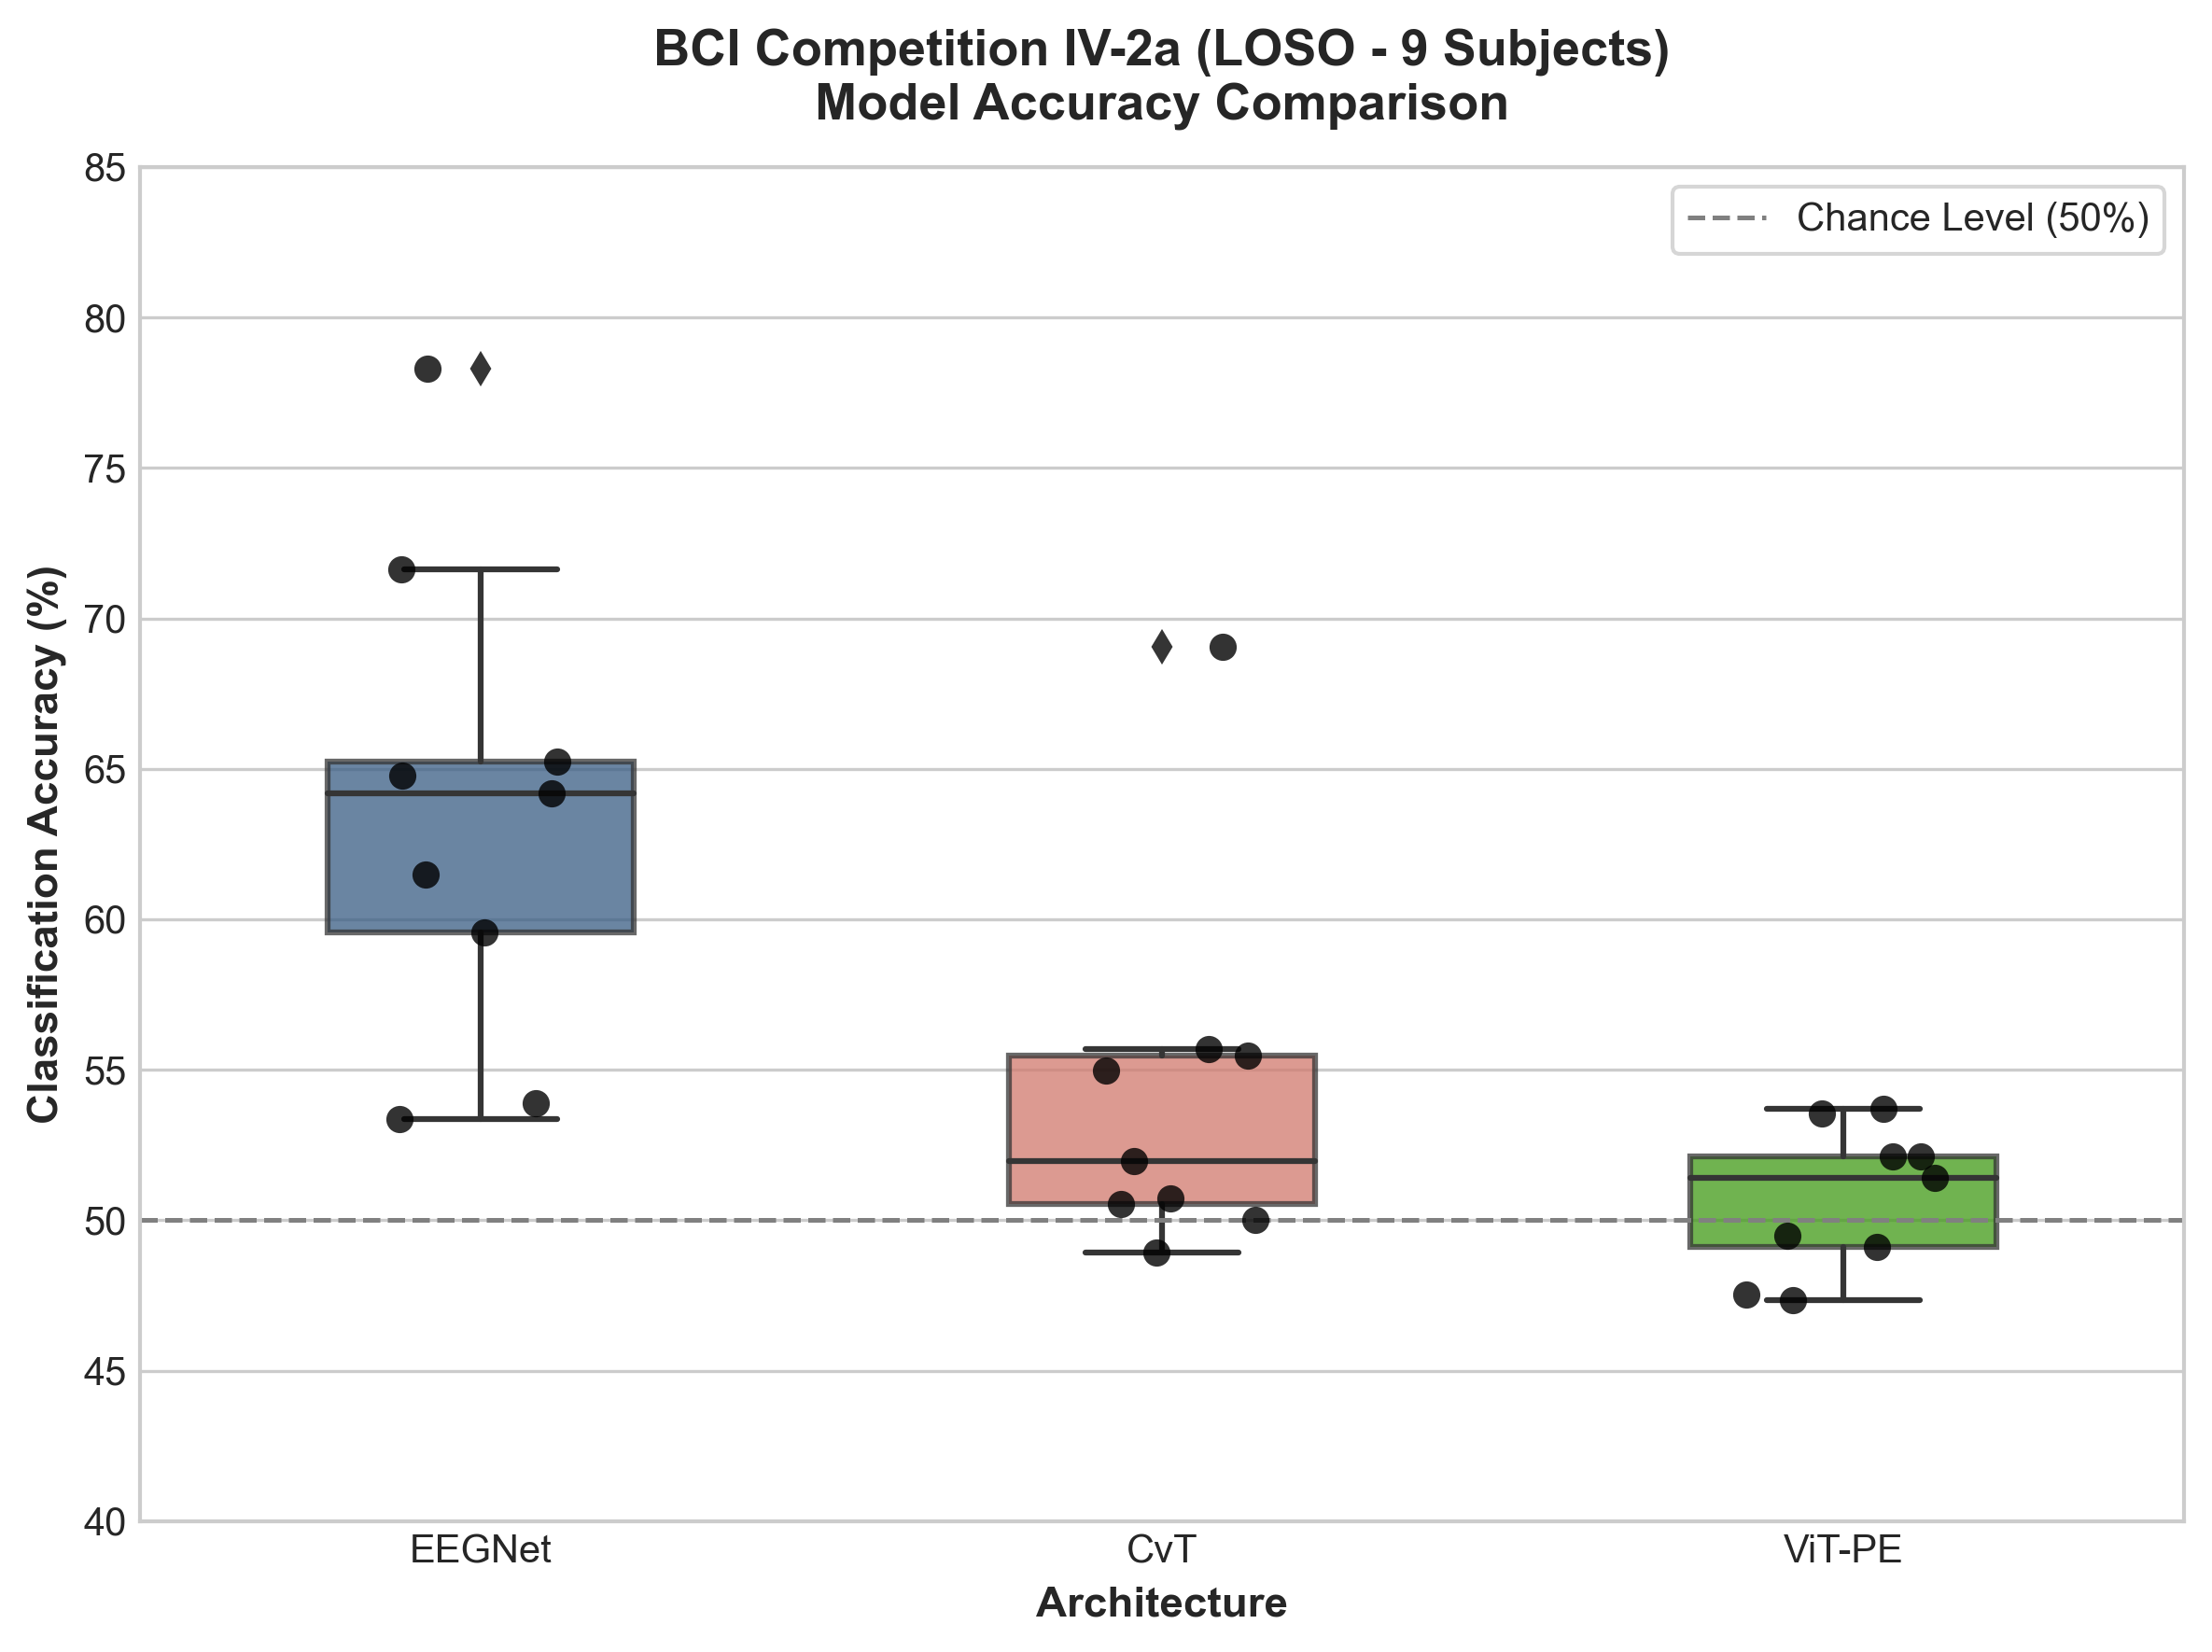


Figures successfully saved to:
1. ../results/bci2a_loso_accuracy_boxplot.png
2. ../results/bci2a_loso_accuracy_boxplot.pdf


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon, norm

# =========================================================
# 1. Directory Setup & Data Loading
# =========================================================
results_dir = os.path.join("..", "results")
models = ["eegnet", "cvt", "vit_pe"]

# Load raw fold performance dataframes
eegnet_df = pd.read_csv(os.path.join(results_dir, "eegnet_loso_fold_performance.csv"))
cvt_df = pd.read_csv(os.path.join(results_dir, "cvt_loso_fold_performance.csv"))
vit_df = pd.read_csv(os.path.join(results_dir, "vit_pe_loso_fold_performance.csv"))

# Verify subject alignment across all 9 LOSO folds
# (Fixed: Added 'test_subject' to detect the exact column saved by training pipeline)
id_col = None
for col_candidate in ['test_subject', 'held_out_subject', 'subject']:
    if col_candidate in eegnet_df.columns:
        id_col = col_candidate
        break

if id_col:
    eegnet_df = eegnet_df.sort_values(id_col).reset_index(drop=True)
    cvt_df = cvt_df.sort_values(id_col).reset_index(drop=True)
    vit_df = vit_df.sort_values(id_col).reset_index(drop=True)
    assert (eegnet_df[id_col].values == cvt_df[id_col].values).all(), "Folds alignment error between EEGNet and CvT!"
    assert (eegnet_df[id_col].values == vit_df[id_col].values).all(), "Folds alignment error between EEGNet and ViT-PE!"
    print(f"Verified strict subject alignment across all 9 folds using column '{id_col}'.")
else:
    print("Warning: No subject ID column found; assuming positional alignment across 9 folds.")

# =========================================================
# 2. Generate and Save Summary Table (Mean ± Std)
# =========================================================
summary_data = []
model_dfs = {"EEGNET": eegnet_df, "CVT": cvt_df, "VIT_PE": vit_df}

for m_name, df in model_dfs.items():
    summary_data.append({
        "Model": m_name,
        "Accuracy (%)": f"{df['accuracy'].mean() * 100:.2f} ± {df['accuracy'].std() * 100:.2f}",
        "F1-Score (%)": f"{df['f1'].mean() * 100:.2f} ± {df['f1'].std() * 100:.2f}",
        "ROC-AUC (%)": f"{df['roc_auc'].mean() * 100:.2f} ± {df['roc_auc'].std() * 100:.2f}",
        "Specificity (%)": f"{df['specificity'].mean() * 100:.2f} ± {df['specificity'].std() * 100:.2f}",
        "Precision (%)": f"{df['precision'].mean() * 100:.2f} ± {df['precision'].std() * 100:.2f}",
        "Recall (%)": f"{df['recall'].mean() * 100:.2f} ± {df['recall'].std() * 100:.2f}",
        "Mean Train Time (s)": f"{df['train_duration_sec'].mean():.1f}s"
    })

summary_table = pd.DataFrame(summary_data)
print("\n--- Summary Performance Table (LOSO - 9 Subjects) ---")
display(summary_table)

summary_csv_path = os.path.join(results_dir, "bci2a_loso_summary_metrics.csv")
summary_table.to_csv(summary_csv_path, index=False)
print(f"Saved summary metrics to: {summary_csv_path}")

# =========================================================
# 3. Wilcoxon Signed-Rank Test & Holm-Bonferroni Correction
# =========================================================
comparisons = [
    ("CvT", "EEGNet", cvt_df["accuracy"].values, eegnet_df["accuracy"].values),
    ("ViT-PE", "EEGNet", vit_df["accuracy"].values, eegnet_df["accuracy"].values),
    ("CvT", "ViT-PE", cvt_df["accuracy"].values, vit_df["accuracy"].values)
]

stat_rows = []
n_pairs = len(eegnet_df)

for m1_name, m2_name, m1_acc, m2_acc in comparisons:
    diff = m1_acc - m2_acc
    stat, p_val = wilcoxon(m1_acc, m2_acc)
    
    # Compute approximate Z-score and effect size (r = Z / sqrt(N))
    z_score = norm.ppf(1 - p_val / 2) if p_val < 1.0 else 0.0
    effect_r = z_score / np.sqrt(n_pairs)
    
    # Determine superior model direction
    mean_diff = np.mean(diff) * 100
    if p_val < 0.05:
        superior = m1_name if mean_diff > 0 else m2_name
    else:
        superior = "No Significant Difference"
        
    stat_rows.append({
        "Comparison": f"{m1_name} vs {m2_name}",
        "Mean Diff (%)": round(mean_diff, 2),
        "Wilcoxon W": stat,
        "p_raw": p_val,
        "Effect Size (r)": round(effect_r, 3),
        "Superior Model": superior
    })

stat_df = pd.DataFrame(stat_rows)

# Apply Holm-Bonferroni step-down correction for multiple comparisons
sorted_indices = np.argsort(stat_df["p_raw"].values)
m = len(stat_df)
holm_p = np.empty(m)

for rank, idx in enumerate(sorted_indices):
    holm_p[idx] = min(1.0, (m - rank) * stat_df.loc[idx, "p_raw"])
    if rank > 0:
        prev_idx = sorted_indices[rank - 1]
        holm_p[idx] = max(holm_p[idx], holm_p[prev_idx])

stat_df["p_holm"] = holm_p
stat_df["Significant (p_holm < 0.05)"] = stat_df["p_holm"] < 0.05

# Reorder columns for optimal readability and display
stat_df = stat_df[["Comparison", "Superior Model", "Mean Diff (%)", "Wilcoxon W", "p_raw", "p_holm", "Effect Size (r)", "Significant (p_holm < 0.05)"]]
print("\n--- Statistical Significance Test Results (Holm-Bonferroni Corrected) ---")
display(stat_df)

stat_csv_path = os.path.join(results_dir, "bci2a_statistical_significance_results.csv")
stat_df.to_csv(stat_csv_path, index=False)
print(f"Saved statistical test results to: {stat_csv_path}")

# =========================================================
# 4. Publication-Quality Boxplot & Stripplot Visualization
# =========================================================
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

plot_data = pd.DataFrame({
    "Model": ["EEGNet"] * 9 + ["CvT"] * 9 + ["ViT-PE"] * 9,
    "Accuracy": np.concatenate([eegnet_df["accuracy"] * 100, cvt_df["accuracy"] * 100, vit_df["accuracy"] * 100])
})

palette = {"EEGNet": "#2b5c8f", "CvT": "#e26d5c", "ViT-PE": "#38b000"}

# Render Boxplot showing distribution across 9 subjects
sns.boxplot(
    data=plot_data, x="Model", y="Accuracy",
    palette=palette, width=0.45, showcaps=True,
    boxprops=dict(alpha=0.75), ax=ax
)

# Overlay individual fold/subject performance points
sns.stripplot(
    data=plot_data, x="Model", y="Accuracy",
    color="black", size=7, jitter=0.15, alpha=0.8, ax=ax
)

# Reference line for random chance level (50%)
ax.axhline(50, color='gray', linestyle='--', linewidth=1.2, label='Chance Level (50%)')

ax.set_title("BCI Competition IV-2a (LOSO - 9 Subjects)\nModel Accuracy Comparison", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Architecture", fontsize=11, fontweight='bold')
ax.set_ylabel("Classification Accuracy (%)", fontsize=11, fontweight='bold')
ax.set_ylim(40, 85)
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()

# Save high-resolution figures (PNG and PDF) for manuscript and reviewer response
fig_png = os.path.join(results_dir, "bci2a_loso_accuracy_boxplot.png")
fig_pdf = os.path.join(results_dir, "bci2a_loso_accuracy_boxplot.pdf")
plt.savefig(fig_png, dpi=300, bbox_inches='tight')
plt.savefig(fig_pdf, bbox_inches='tight')
plt.show()
print(f"\nFigures successfully saved to:\n1. {fig_png}\n2. {fig_pdf}")